# Probabilistic SMS Spam Detection
**BAMAT207 Probability and Statistics**  
**Student:** Kushal Bagla  
**Roll number:** 25BAI0044  
**Topic:** Probability and Random Variables  
**Submission deadline:** 27 October 2026

This project uses probability and a Multinomial Naive Bayes classifier to distinguish spam from genuine SMS messages. This notebook currently completes **Activities 1 to 7**: dataset handling, probability analysis, data preparation, model training and evaluation. Interactive SMS prediction will follow in the final stage.

## Running this notebook
Run cells in order from the top. Locally, open this notebook from the repository root using the Python environment described in README.md. The source dataset is included in `data/raw`. On Google Colab, upload this notebook and run all cells; it downloads the same official UCI data if the local file is absent. Pandas, NumPy, Matplotlib, scikit-learn and joblib are required and are normally preinstalled in Colab. The repository requirements.txt records the verified versions; different versions may change results. The loader and cleaning functions are included here so the notebook can run independently of the repository's Python modules.

Outputs are saved relative to the notebook's current working directory. The model results below are measured on a held-out test set.

## Dataset source
Almeida, T. and Hidalgo, J. (2011). *SMS Spam Collection*. UCI Machine Learning Repository. https://doi.org/10.24432/C5CC84

Source: https://archive.ics.uci.edu/dataset/228/sms+spam+collection  
Licence listed by UCI: [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/).

The original file contains one SMS record per physical line, with a label followed by a tab and the message. We split only at the first tab and preserve quotation marks and any further tabs as message content. A SHA-256 check ensures that the file matches the verified source download.

## 1 Dataset Handling
### Load the SMS messages and labels
The following reusable functions match `src/data.py`. Cleaning removes records with missing or blank labels/messages, checks for unexpected or conflicting labels, removes exact duplicate message text and encodes Ham = 0 and Spam = 1. Case, punctuation and whitespace in nonblank SMS text are preserved. Deduplication happens before the future training/test split to avoid placing identical messages in both sets.

In [1]:
"""Load the official SMS Spam Collection without CSV quoting assumptions."""
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import pandas as pd

DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
SOURCE_SHA256 = "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d"


def download_dataset(path: Path) -> Path:
    """Download the official file if absent; verify cached or downloaded bytes."""
    path = Path(path)
    if path.exists():
        content = path.read_bytes()
    else:
        with urlopen(DATA_URL, timeout=60) as response:
            with ZipFile(BytesIO(response.read())) as archive:
                content = archive.read("SMSSpamCollection")
    if sha256(content).hexdigest() != SOURCE_SHA256:
        raise ValueError("Dataset checksum differs from the verified UCI source.")
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(content)
    return path


def load_dataset(path: Path) -> pd.DataFrame:
    """Split each physical record at its first tab, preserving SMS text."""
    records = []
    for line_number, line in enumerate(Path(path).read_text(encoding="utf-8").splitlines(), 1):
        if "\t" not in line:
            raise ValueError(f"Source line {line_number} has no label separator.")
        label, message = line.split("\t", 1)
        records.append({"source_line": line_number, "label": label, "message": message})
    return pd.DataFrame(records, columns=["source_line", "label", "message"])


def clean_dataset(raw: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Remove missing/blank records and exact duplicate SMS messages.

    Preserve case, punctuation and whitespace in nonblank SMS text. Detect
    conflicting labels before deduplication rather than choosing one silently.
    """
    required = {"source_line", "label", "message"}
    if not required.issubset(raw.columns):
        raise ValueError(f"Required columns: {sorted(required)}")
    missing = raw[["label", "message"]].isna()
    blank = raw[["label", "message"]].apply(lambda col: col.fillna("").str.strip().eq(""))
    invalid = (missing | blank).any(axis=1)
    valid = raw.loc[~invalid].copy()
    unknown = set(valid["label"]) - {"spam", "ham"}
    if unknown:
        raise ValueError(f"Unexpected labels: {sorted(unknown)}")
    conflicts = valid.groupby("message")["label"].nunique().gt(1)
    if conflicts.any():
        raise ValueError("Identical messages have conflicting labels; inspect the source.")
    duplicate_count = int(valid.duplicated(subset="message").sum())
    clean = valid.drop_duplicates(subset="message", keep="first").copy()
    clean["target"] = clean["label"].map({"ham": 0, "spam": 1}).astype("int64")
    clean = clean.reset_index(drop=True)
    summary = {
        "raw_records": int(len(raw)),
        "missing_values": {key: int(value) for key, value in missing.sum().items()},
        "blank_non_null_values": {
            key: int(value) for key, value in (blank & ~missing).sum().items()
        },
        "removed_missing_or_blank_records": int(invalid.sum()),
        "removed_duplicate_messages": duplicate_count,
        "clean_records": int(len(clean)),
        "raw_class_counts": {key: int(value) for key, value in raw["label"].value_counts().items()},
        "clean_class_counts": {key: int(value) for key, value in clean["label"].value_counts().items()},
        "label_encoding": {"ham": 0, "spam": 1},
        "duplicate_rule": "Exact message text; retain the first occurrence",
    }
    return clean, summary


In [2]:
raw_path = download_dataset(Path("data/raw/SMSSpamCollection"))
raw = load_dataset(raw_path)
print(f"Loaded {len(raw):,} records from the verified UCI file.")
print("Raw class counts:")
print(raw["label"].value_counts().to_string())

Loaded 5,574 records from the verified UCI file.
Raw class counts:
label
ham     4827
spam     747


### Check missing values and remove duplicate messages
Missing values and whitespace-only fields are counted separately. Exact duplicates retain their first occurrence. The source line number is retained so each cleaned record can be traced back to the raw file.

In [3]:
import json

clean, summary = clean_dataset(raw)
print(json.dumps(summary, indent=2))
assert clean["message"].is_unique
assert not clean[["label", "message", "target"]].isna().any().any()
assert set(clean["target"].unique()) == {0, 1}
assert len(raw) == len(clean) + summary["removed_missing_or_blank_records"] + summary["removed_duplicate_messages"]
print("Integrity checks passed.")

{
  "raw_records": 5574,
  "missing_values": {
    "label": 0,
    "message": 0
  },
  "blank_non_null_values": {
    "label": 0,
    "message": 0
  },
  "removed_missing_or_blank_records": 0,
  "removed_duplicate_messages": 403,
  "clean_records": 5171,
  "raw_class_counts": {
    "ham": 4827,
    "spam": 747
  },
  "clean_class_counts": {
    "ham": 4518,
    "spam": 653
  },
  "label_encoding": {
    "ham": 0,
    "spam": 1
  },
  "duplicate_rule": "Exact message text; retain the first occurrence"
}
Integrity checks passed.


### Cleaned dataset summary
The original dataset contains **5,574 records**: 4,827 ham and 747 spam. There are no missing or blank labels/messages. Removing **403 duplicate messages** leaves **5,171 unique messages**, comprising **4,518 ham** and **653 spam**. These cleaned records will be the basis of the probability calculations and later model split.

Deduplication uses exact message text. Similar messages with different wording or formatting remain distinct; this rule is explicit and reproducible. No labels conflict for identical messages in this source.

In [4]:
counts = pd.DataFrame({
    "Original": raw["label"].value_counts(),
    "Cleaned": clean["label"].value_counts(),
}).reindex(["ham", "spam"])
counts["Duplicates removed"] = counts["Original"] - counts["Cleaned"]
print(counts.to_string())
print("\nNumeric labels: ham = 0; spam = 1")

       Original  Cleaned  Duplicates removed
label                                       
ham        4827     4518                 309
spam        747      653                  94

Numeric labels: ham = 0; spam = 1


### Save the cleaned dataset and summary
The CSV includes `source_line`, `label`, `message` and `target`. The JSON summary records all cleaning counts and the duplicate rule. CSV quoting preserves messages containing commas, quotes and tabs; load the exported file with `pandas.read_csv`.

In [5]:
Path("data/processed").mkdir(parents=True, exist_ok=True)
Path("reports").mkdir(parents=True, exist_ok=True)
clean.to_csv("data/processed/sms_cleaned.csv", index=False)
Path("reports/dataset_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
restored = pd.read_csv("data/processed/sms_cleaned.csv", keep_default_na=False)
pd.testing.assert_frame_equal(clean, restored)
print("Saved cleaned dataset and summary; CSV round-trip check passed.")

Saved cleaned dataset and summary; CSV round-trip check passed.


## 2 Dataset Analysis
All probabilities below describe a uniformly selected message from the **5,171 cleaned records**. These are empirical dataset proportions, not guarantees about new messages.

$$P(Spam)=\frac{N_{spam}}{N},\qquad P(Ham)=\frac{N_{ham}}{N}.$$

The functions below also calculate the word probabilities needed in Activity 3. They match `src/probability.py`.

In [6]:
"""Empirical message-level probabilities for the cleaned SMS collection."""
import re

import numpy as np
import pandas as pd

SUSPICIOUS_WORDS = ("free", "prize", "win", "urgent", "offer")


def analyze_probabilities(clean: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Count whole-word presence once per message, ignoring letter case.

    Python regex word boundaries exclude substrings such as 'win' in 'winning'.
    Undefined conditional probabilities are NaN, never a manufactured zero.
    """
    if clean.empty:
        raise ValueError("Probability analysis requires at least one message.")
    if clean[["message", "target"]].isna().any().any():
        raise ValueError("Messages and targets must not be missing.")
    if not clean["target"].isin([0, 1]).all():
        raise ValueError("Targets must be ham = 0 or spam = 1.")
    total = len(clean)
    spam = clean["target"].eq(1)
    n_spam = int(spam.sum())
    p_spam = n_spam / total
    rows = []
    for word in SUSPICIOUS_WORDS:
        contains = clean["message"].str.contains(r"\b" + re.escape(word) + r"\b", case=False, regex=True)
        n_word = int(contains.sum())
        n_joint = int((contains & spam).sum())
        p_word = n_word / total
        p_word_given_spam = n_joint / n_spam if n_spam else np.nan
        direct = n_joint / n_word if n_word else np.nan
        bayes = p_word_given_spam * p_spam / p_word if n_spam and n_word else np.nan
        rows.append({
            "word": word,
            "messages_with_word": n_word,
            "spam_with_word": n_joint,
            "ham_with_word": n_word - n_joint,
            "p_word": p_word,
            "p_word_given_spam": p_word_given_spam,
            "p_spam_given_word": direct,
            "bayes_p_spam_given_word": bayes,
        })
    summary = {
        "total_messages": total,
        "spam_messages": n_spam,
        "ham_messages": total - n_spam,
        "p_spam": p_spam,
        "p_ham": 1 - p_spam,
        "expectation_Y": p_spam,
        "variance_Y": p_spam * (1 - p_spam),
        "empirical_mean_Y": float(np.mean(clean["target"].to_numpy())),
        "empirical_population_variance_Y": float(np.var(clean["target"].to_numpy(), ddof=0)),
    }
    return pd.DataFrame(rows), summary


In [7]:
word_probabilities, probability_summary = analyze_probabilities(clean)
N = probability_summary["total_messages"]
S = probability_summary["spam_messages"]
H = probability_summary["ham_messages"]
p = probability_summary["p_spam"]
print(f"P(Spam) = {S}/{N} = {p:.8f} ({p:.4%})")
print(f"P(Ham) = {H}/{N} = {probability_summary['p_ham']:.8f} ({probability_summary['p_ham']:.4%})")
assert np.isclose(probability_summary["p_spam"] + probability_summary["p_ham"], 1.0)

P(Spam) = 653/5171 = 0.12628118 (12.6281%)
P(Ham) = 4518/5171 = 0.87371882 (87.3719%)


Matplotlib is building the font cache; this may take a moment.


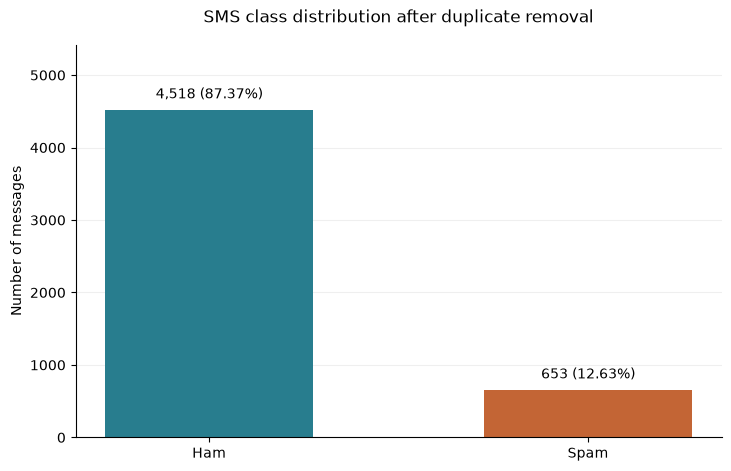

In [8]:
import matplotlib.pyplot as plt

Path("reports/figures").mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(7.2, 4.6), layout="constrained")
bars = ax.bar(["Ham", "Spam"], [H, S], color=["#287D8E", "#C36535"], width=0.55)
ax.set_title("SMS class distribution after duplicate removal", pad=16)
ax.set_ylabel("Number of messages")
ax.set_ylim(0, max(H, S) * 1.2)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
ax.bar_label(bars, labels=[f"{H:,} ({H/N:.2%})", f"{S:,} ({S/N:.2%})"], padding=6)
fig.savefig("reports/figures/class_distribution.png", dpi=180)
plt.show()
plt.close(fig)

## 3 Word Based Probability Analysis
For each of **free, prize, win, urgent and offer**, let $W$ mean that a message contains that whole word, ignoring letter case. A word is counted **once per message**, even if repeated. Python regular-expression word boundaries are used: `FREE!` matches `free`, while `freedom` does not; `winning` does not match `win`. No stemming is used.

Let $N_W$ be the number of messages containing the word and $N_{S,W}$ the number of spam messages containing it. Then

$$P(Spam\mid W)=\frac{N_{S,W}}{N_W}.$$

Bayes' theorem gives the same result:

$$P(Spam\mid W)=\frac{P(W\mid Spam)P(Spam)}{P(W)}
=\frac{(N_{S,W}/N_{spam})(N_{spam}/N)}{N_W/N}.$$

All counts use the same cleaned population. A conditional probability is undefined if its conditioning event has zero observations; the code returns NaN in that situation. All five specified words occur in this dataset.

In [9]:
print(word_probabilities.to_string(index=False, float_format=lambda x: f"{x:.8f}"))
assert (word_probabilities["messages_with_word"] > 0).all()
assert np.allclose(word_probabilities["p_spam_given_word"], word_probabilities["bayes_p_spam_given_word"], atol=1e-12, rtol=0)
for row in word_probabilities.itertuples(index=False):
    print(f"\n{row.word.upper()}")
    print(f"Direct: {row.spam_with_word}/{row.messages_with_word} = {row.p_spam_given_word:.8f}")
    print(f"Bayes: [({row.spam_with_word}/{S}) × ({S}/{N})] / ({row.messages_with_word}/{N}) = {row.bayes_p_spam_given_word:.8f}")
print("\nAll five Bayes calculations agree with the direct conditional probabilities.")

  word  messages_with_word  spam_with_word  ham_with_word     p_word  p_word_given_spam  p_spam_given_word  bayes_p_spam_given_word
  free                 203             148             55 0.03925740         0.22664625         0.72906404               0.72906404
 prize                  73              73              0 0.01411719         0.11179173         1.00000000               1.00000000
   win                  55              49              6 0.01063624         0.07503828         0.89090909               0.89090909
urgent                  62              57              5 0.01198994         0.08728943         0.91935484               0.91935484
 offer                  30              24              6 0.00580159         0.03675345         0.80000000               0.80000000

FREE
Direct: 148/203 = 0.72906404
Bayes: [(148/653) × (653/5171)] / (203/5171) = 0.72906404

PRIZE
Direct: 73/73 = 1.00000000
Bayes: [(73/653) × (653/5171)] / (73/5171) = 1.00000000

WIN
Direct: 49/55 = 0.89

These probabilities describe spam prevalence among messages containing a particular word. They do not give the probability of spam for an entire new message and do not establish causation. A word can occur in both spam and ham; the later classifier will combine word-count features. These full-dataset calculations are descriptive; they will not be used to choose model settings based on test-set results.

## 4 Random Variable Analysis
Define the spam indicator:

$$Y=\begin{cases}1,&\text{if the message is spam},\\0,&\text{if the message is ham}.\end{cases}$$

For a uniformly selected cleaned message, $Y$ is Bernoulli with $p=P(Spam)$.

$$E(Y)=0(1-p)+1p=p.$$

Since $Y^2=Y$, $E(Y^2)=p$, so

$$Var(Y)=E(Y^2)-[E(Y)]^2=p-p^2=p(1-p).$$

The numerical cross-check below uses **population variance** (`ddof=0`) because the empirical distribution assigns probability $1/N$ to each cleaned message. A sample variance with denominator $N-1$ would answer a different question.

In [10]:
print(f"E(Y) = {S}/{N} = {probability_summary['expectation_Y']:.8f}")
print(f"Var(Y) = ({S}/{N}) × ({H}/{N}) = {probability_summary['variance_Y']:.8f}")
print(f"Mean of target labels = {probability_summary['empirical_mean_Y']:.8f}")
print(f"Population variance of target labels = {probability_summary['empirical_population_variance_Y']:.8f}")
assert np.isclose(probability_summary["expectation_Y"], probability_summary["empirical_mean_Y"])
assert np.isclose(probability_summary["variance_Y"], probability_summary["empirical_population_variance_Y"])
word_probabilities.to_csv("reports/word_probabilities.csv", index=False, float_format="%.12g")
Path("reports/probability_summary.json").write_text(json.dumps(probability_summary, indent=2) + "\n", encoding="utf-8")
print("Saved word probabilities, class probabilities and Bernoulli moments.")

E(Y) = 653/5171 = 0.12628118
Var(Y) = (653/5171) × (4518/5171) = 0.11033425
Mean of target labels = 0.12628118
Population variance of target labels = 0.11033425
Saved word probabilities, class probabilities and Bernoulli moments.


## 5 Data Preparation
Use 80% of the cleaned messages for training and 20% for testing, with class stratification and `random_state=42`. Integer rounding means the test set has 1,035 records and the training set has 4,136. The fixed seed makes the split reproducible.

The same message cannot appear in both sets because exact duplicates have already been removed. The split manifest records each original source line and its assigned partition. The code below matches `src/model.py` and includes the training and evaluation helpers used in the following activities.

In [11]:
"""Reproducible data preparation, training and evaluation for SMS detection."""
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42


def split_messages(clean: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Reserve 20% for testing with class stratification and a fixed seed."""
    if clean["message"].duplicated().any():
        raise ValueError("Remove duplicate messages before splitting.")
    train, test = train_test_split(
        clean, test_size=0.20, random_state=RANDOM_STATE, stratify=clean["target"]
    )
    train, test = train.copy(), test.copy()
    if set(train["source_line"]) & set(test["source_line"]):
        raise ValueError("Source records overlap between training and testing.")
    return train, test


from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


def train_model(train: pd.DataFrame) -> Pipeline:
    """Fit word counts and MultinomialNB using training messages only."""
    model = Pipeline([
        ("vectorizer", CountVectorizer()),
        ("classifier", MultinomialNB()),
    ])
    model.fit(train["message"], train["target"])
    return model


def evaluate_model(model: Pipeline, test: pd.DataFrame) -> tuple[dict, pd.DataFrame]:
    """Evaluate untouched test records; spam is the positive class."""
    predictions = model.predict(test["message"])
    probabilities = model.predict_proba(test["message"])
    class_columns = {int(label): i for i, label in enumerate(model.classes_)}
    matrix = confusion_matrix(test["target"], predictions, labels=[0, 1])
    tn, fp, fn, tp = (int(value) for value in matrix.ravel())
    report = classification_report(
        test["target"], predictions, labels=[0, 1], target_names=["ham", "spam"],
        output_dict=True, zero_division=0,
    )
    metrics = {
        "test_messages": len(test),
        "accuracy": float(accuracy_score(test["target"], predictions)),
        "spam_precision": float(report["spam"]["precision"]),
        "spam_recall": float(report["spam"]["recall"]),
        "spam_f1": float(report["spam"]["f1-score"]),
        "always_ham_baseline_accuracy": float(test["target"].eq(0).mean()),
        "confusion_matrix": matrix.tolist(),
        "matrix_label_order": ["ham", "spam"],
        "matrix_orientation": "rows = actual; columns = predicted",
        "true_negatives": tn, "false_positives": fp,
        "false_negatives": fn, "true_positives": tp,
        "classification_report": report,
    }
    results = test[["source_line", "label", "message", "target"]].copy()
    results["predicted_target"] = predictions
    results["predicted_label"] = np.where(predictions == 1, "spam", "ham")
    results["p_ham"] = probabilities[:, class_columns[0]]
    results["p_spam"] = probabilities[:, class_columns[1]]
    results["error_type"] = np.select(
        [(results["target"] == 1) & (predictions == 0),
         (results["target"] == 0) & (predictions == 1)],
        ["false_negative", "false_positive"], default="correct",
    )
    return metrics, results


In [12]:
train, test = split_messages(clean)
split_counts = pd.DataFrame({
    "Training": train["label"].value_counts(),
    "Testing": test["label"].value_counts(),
}).reindex(["ham", "spam"])
print(split_counts.to_string())
print(f"\nTraining: {len(train):,} ({len(train)/len(clean):.4%})")
print(f"Testing: {len(test):,} ({len(test)/len(clean):.4%})")
print(f"Training spam share: {train.target.mean():.4%}")
print(f"Testing spam share: {test.target.mean():.4%}")
assert set(train.source_line).isdisjoint(test.source_line)
assert set(train.message).isdisjoint(test.message)
assert len(train) + len(test) == len(clean)
manifest = pd.concat([
    train[["source_line", "label", "target"]].assign(partition="train"),
    test[["source_line", "label", "target"]].assign(partition="test"),
]).sort_values("source_line")
manifest.to_csv("reports/split_manifest.csv", index=False)

       Training  Testing
label                   
ham        3614      904
spam        522      131

Training: 4,136 (79.9845%)
Testing: 1,035 (20.0155%)
Training spam share: 12.6209%
Testing spam share: 12.6570%


## 6 Model Building
The pipeline contains `CountVectorizer()` followed by `MultinomialNB()`, using their default settings. CountVectorizer lowercases text and produces discrete word-count features; its default token pattern retains tokens with at least two word characters. No stop-word removal or stemming is applied. The classifier uses additive smoothing with alpha = 1.

Fitting the pipeline on training messages fits both the vocabulary and classifier. Test messages are only transformed using the learned vocabulary; unseen test words are ignored. The five suspicious words from the descriptive analysis do not restrict the vocabulary. No model settings are chosen using test-set scores.

In [13]:
model = train_model(train)
vectorizer = model.named_steps["vectorizer"]
classifier = model.named_steps["classifier"]
print(f"Training vocabulary size: {len(vectorizer.vocabulary_):,}")
print(f"Training feature matrix shape: {vectorizer.transform(train.message).shape}")
print(f"Classifier: {classifier}")
assert int(classifier.class_count_.sum()) == len(train)
vocabulary_before_evaluation = dict(vectorizer.vocabulary_)

Training vocabulary size: 7,669
Training feature matrix shape: (4136, 7669)
Classifier: MultinomialNB()


## 7 Model Evaluation
Evaluate once on the held-out test messages. Spam (1) is the positive class. Rows of the confusion matrix are actual labels; columns are predicted labels, in the order Ham, Spam.

- True negative (TN): ham correctly predicted as ham.
- False positive (FP): genuine message incorrectly flagged as spam.
- False negative (FN): spam incorrectly classified as genuine.
- True positive (TP): spam correctly predicted as spam.

Accuracy = (TP + TN) / total. Spam precision = TP / (TP + FP). Spam recall = TP / (TP + FN). F1 = 2 × precision × recall / (precision + recall).

Because ham is the majority class, also report the accuracy of always predicting ham. Per-class precision, recall and F1 provide information that accuracy alone cannot.

In [14]:
metrics, test_predictions = evaluate_model(model, test)
print(f"Accuracy: {metrics['accuracy']:.4%}")
print(f"Spam precision: {metrics['spam_precision']:.4%}")
print(f"Spam recall: {metrics['spam_recall']:.4%}")
print(f"Spam F1-score: {metrics['spam_f1']:.4f}")
print(f"Always-ham baseline accuracy: {metrics['always_ham_baseline_accuracy']:.4%}")
print("\nClassification report:")
print(classification_report(test.target, test_predictions.predicted_target, labels=[0, 1], target_names=["ham", "spam"], digits=4, zero_division=0))
print(f"Missed spam (FN): {metrics['false_negatives']}")
print(f"Genuine messages flagged as spam (FP): {metrics['false_positives']}")
assert vocabulary_before_evaluation == vectorizer.vocabulary_
assert np.allclose(test_predictions[["p_ham", "p_spam"]].sum(axis=1), 1)
assert sum(sum(row) for row in metrics["confusion_matrix"]) == len(test)

Accuracy: 98.0676%
Spam precision: 95.1220%
Spam recall: 89.3130%
Spam F1-score: 0.9213
Always-ham baseline accuracy: 87.3430%

Classification report:
              precision    recall  f1-score   support

         ham     0.9846    0.9934    0.9890       904
        spam     0.9512    0.8931    0.9213       131

    accuracy                         0.9807      1035
   macro avg     0.9679    0.9432    0.9551      1035
weighted avg     0.9804    0.9807    0.9804      1035

Missed spam (FN): 14
Genuine messages flagged as spam (FP): 6


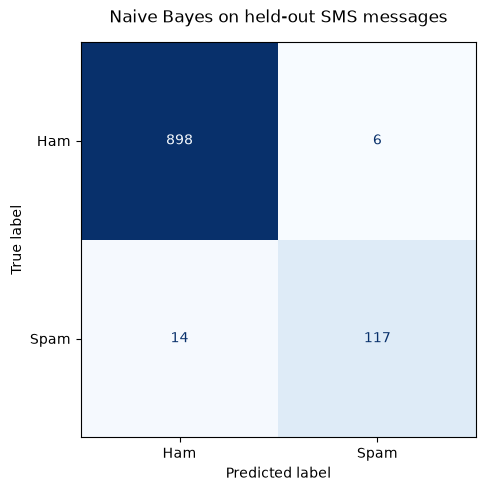

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(5.6, 4.8), layout="constrained")
ConfusionMatrixDisplay(np.array(metrics["confusion_matrix"]), display_labels=["Ham", "Spam"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Naive Bayes on held-out SMS messages", pad=14)
fig.savefig("reports/figures/confusion_matrix.png", dpi=180)
plt.show()
plt.close(fig)

### Inspect both error types
The full error export contains every misclassified test message with its source line, actual label, prediction and model probabilities. The following cell displays up to three examples of each error type. Model probabilities are estimates from Naive Bayes and have not been calibrated; they should not be interpreted as guaranteed real-world confidence.

In [16]:
errors = test_predictions.loc[test_predictions.error_type != "correct"].copy()
for error_type in ["false_negative", "false_positive"]:
    subset = errors.loc[errors.error_type == error_type]
    print(f"\n{error_type}: {len(subset)} messages")
    for row in subset.head(3).itertuples(index=False):
        print(f"Source line {row.source_line}; actual={row.label}; predicted={row.predicted_label}; P(spam)={row.p_spam:.6f}")
        print(row.message)
        print()
assert len(errors) == metrics["false_negatives"] + metrics["false_positives"]


false_negative: 14 messages
Source line 4822; actual=spam; predicted=ham; P(spam)=0.369603
Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo

Source line 2771; actual=spam; predicted=ham; P(spam)=0.453176
Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner

Source line 3531; actual=spam; predicted=ham; P(spam)=0.004897
Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!


false_positive: 6 messages
Source line 4863; actual=ham; predicted=spam; P(spam)=0.946751
Nokia phone is lovly..

Source line 4601; actual=ham; predicted=spam; P(spam)=0.871380
Have you laid your airtel line to rest?

Source line 4730; actual=ham; predicted=spam; P(spam)=0.916067
I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to  &lt;#&gt;



### Save the trained model and evaluation outputs
Save the complete pipeline so prediction uses the same fitted vocabulary and classifier. The saved model remains fitted only on training records; the test messages are not used for retraining. Reload it and check that predictions and probabilities match before export is accepted.

Results apply to this single reproducible split of the historical dataset. Similar but non-identical messages may remain across partitions; performance on new, evolving SMS traffic may differ. These results are not a cross-validation estimate.

In [17]:
import joblib
import sklearn
import platform

Path("models").mkdir(exist_ok=True)
joblib.dump(model, "models/sms_naive_bayes.joblib", compress=3)
reloaded = joblib.load("models/sms_naive_bayes.joblib")
assert np.array_equal(model.predict(test.message), reloaded.predict(test.message))
assert np.allclose(model.predict_proba(test.message), reloaded.predict_proba(test.message))
metadata = {
    "random_state": RANDOM_STATE,
    "test_size_requested": 0.2,
    "training_messages": len(train), "test_messages": len(test),
    "training_spam": int(train.target.sum()), "test_spam": int(test.target.sum()),
    "vocabulary_size": len(vectorizer.vocabulary_),
    "python_version": platform.python_version(), "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__, "pandas_version": pd.__version__, "joblib_version": joblib.__version__,
    "raw_dataset_sha256": SOURCE_SHA256,
    "cleaned_csv_sha256": sha256(Path("data/processed/sms_cleaned.csv").read_bytes()).hexdigest(),
    "model_type": "CountVectorizer() + MultinomialNB() with default parameters",
    "fit_scope": "training partition only", "probabilities_calibrated": False,
}
Path("models/training_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
Path("reports/model_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
report_text = classification_report(test.target, test_predictions.predicted_target, labels=[0, 1], target_names=["ham", "spam"], digits=4, zero_division=0)
Path("reports/classification_report.txt").write_text(report_text, encoding="utf-8")
test_predictions.to_csv("reports/test_predictions.csv", index=False, float_format="%.12g")
errors.to_csv("reports/misclassified_messages.csv", index=False, float_format="%.12g")
print("Saved pipeline, metadata, test predictions, errors and evaluation reports.")
print("Reloaded pipeline reproduces predictions and probabilities.")

Saved pipeline, metadata, test predictions, errors and evaluation reports.
Reloaded pipeline reproduces predictions and probabilities.
